<a href="https://colab.research.google.com/github/adrianabratfisch/streaming_churn/blob/master/Estat%C3%ADstica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Carregando o arquivo `clientes_base.csv` e verificando os tipos das colunas

Vamos carregar diretamente o arquivo pelo seu caminho específico e analisar sua estrutura.

In [ ]:
import pandas as pd

caminho_arquivo = '/content/drive/MyDrive/Data Science/clientes_base.csv'

try:
    df = pd.read_csv(caminho_arquivo)
    print("Arquivo carregado com sucesso!")
except Exception as e:
    print(f"Erro ao carregar o arquivo: {e}")

Arquivo carregado com sucesso!


#### Visualizando o DataFrame (Primeiras 5 linhas):

In [ ]:
display(df.head())

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0


#### Verificando os tipos de dados das colunas:

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cliente_id              5025 non-null   int64  
 1   idade                   5025 non-null   int64  
 2   plano                   5025 non-null   object 
 3   ciclo                   5025 non-null   object 
 4   valor_mensal            5025 non-null   float64
 5   regiao                  5025 non-null   object 
 6   canal_aquisicao         5025 non-null   object 
 7   nps                     5025 non-null   int64  
 8   data_assinatura         5025 non-null   object 
 9   data_cancelamento       1516 non-null   object 
 10  data_ultimo_acesso      4975 non-null   object 
 11  data_extracao           5025 non-null   object 
 12  dias_ativos_ult_mes     5025 non-null   int64  
 13  horas_assistidas_total  5025 non-null   float64
 14  motivo_cancelamento     1516 non-null   

### Análise de Distribuição e Valores Únicos

Vamos exibir as contagens exatas e plotar gráficos de barras para as colunas: `plano`, `ciclo`, `regiao` e `canal_aquisicao`.


--- Contagem para a coluna: plano ---
plano
Basico     1385
Padrão     1300
Premium     998
Básico      677
Padrao      665
Name: count, dtype: int64

--- Contagem para a coluna: ciclo ---
ciclo
Mensal    3794
Anual     1231
Name: count, dtype: int64

--- Contagem para a coluna: regiao ---
regiao
Sudeste         2057
Nordeste         964
Sul              938
Centro-oeste     488
Norte            408
?                170
Name: count, dtype: int64

--- Contagem para a coluna: canal_aquisicao ---
canal_aquisicao
Instagram    1018
Google        886
Organico      781
Orgânico      729
Indicacao     556
Ig            529
Indicação     526
Name: count, dtype: int64


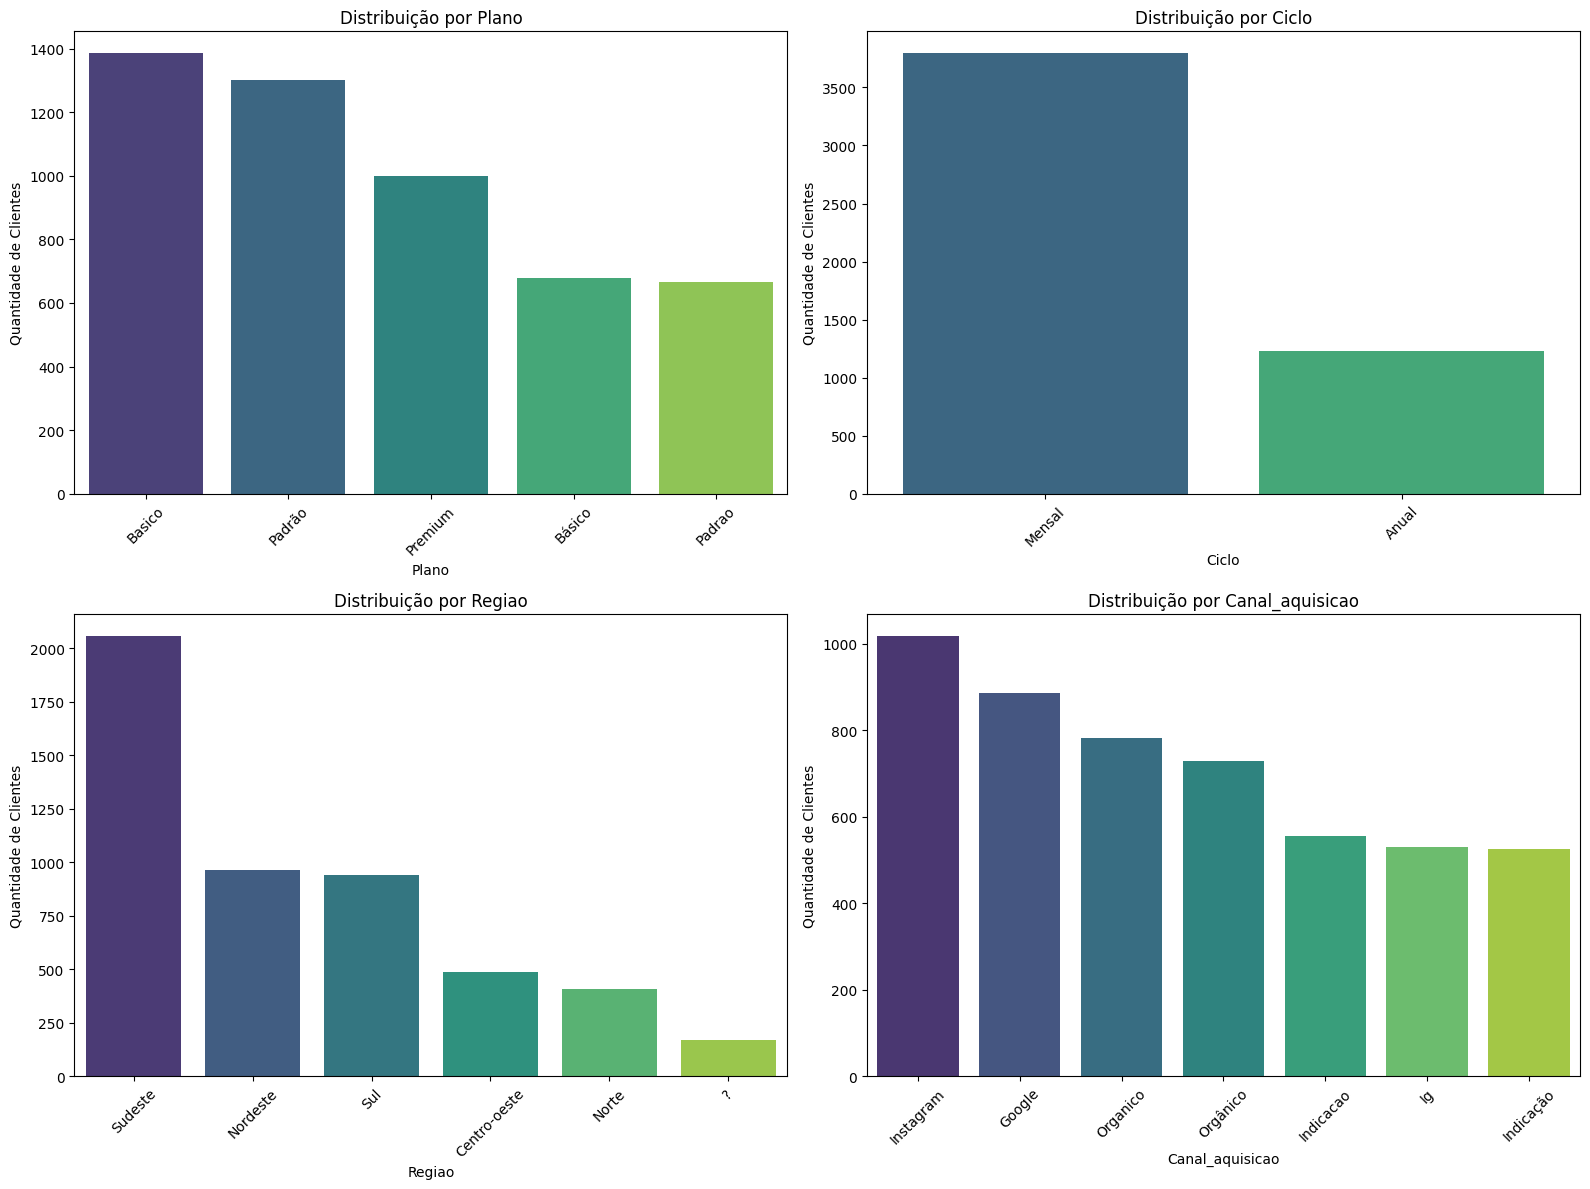

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Configurando o tamanho dos gráficos
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas_analise):
    # Padronização de strings para evitar duplicações por conta de maiúsculas/minúsculas ou espaços
    df[col] = df[col].astype(str).str.strip().str.capitalize()

    # Contagem de valores
    contagem = df[col].value_counts()
    print(f"\n--- Contagem para a coluna: {col} ---")
    print(contagem)

    # Plotagem do gráfico de barras
    sns.barplot(x=contagem.index, y=contagem.values, ax=axes[i], palette='viridis', hue=contagem.index, legend=False)
    axes[i].set_title(f'Distribuição por {col.capitalize()}')
    axes[i].set_xlabel(col.capitalize())
    axes[i].set_ylabel('Quantidade de Clientes')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Respondendo às perguntas e realizando a limpeza de dados

In [ ]:
# 1. Quantidade de nulos em cada coluna
print("=== 1. QUANTIDADE DE NULOS POR COLUNA ===")
nulos_por_coluna = df.isnull().sum()
display(nulos_por_coluna)

# 2. Exemplo do DataFrame onde a coluna regiao é "?"
# Como limpamos o DataFrame no passo anterior, vamos recarregar o df original para garantir consistência
df_original = pd.read_csv('/content/drive/MyDrive/Data Science/clientes_base.csv')

print("\n=== 2. EXEMPLO DE LINHAS ONDE REGIAO É '?' ===")
exemplo_regiao_interrogacao = df_original[df_original['regiao'].astype(str).str.strip() == '?']
display(exemplo_regiao_interrogacao.head(5))

# 3 e 4. Substituições e Padronizações sugeridas
# Vamos aplicar diretamente no nosso DataFrame de trabalho 'df'

# Criando mapeamentos robustos (garantindo tratar variações de maiúsculas/minúsculas e acentos)
df['plano'] = df['plano'].astype(str).str.strip().str.lower()
mapa_plano_ajustado = {
    'basico': 'básico',
    'básico': 'básico',
    'padrao': 'padrão',
    'padrão': 'padrão',
    'premium': 'premium'
}
df['plano'] = df['plano'].replace(mapa_plano_ajustado)

df['canal_aquisicao'] = df['canal_aquisicao'].astype(str).str.strip().str.lower()
mapa_canal_ajustado = {
    'organico': 'orgânico',
    'orgânico': 'orgânico',
    'indicacao': 'indicação',
    'indicação': 'indicação',
    'ig': 'instagram',
    'instagram': 'instagram',
    'google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].replace(mapa_canal_ajustado)

print("\n=== Contagens após as novas substituições ===")
print("\nPlano:")
print(df['plano'].value_counts())
print("\nCanal de Aquisição:")
print(df['canal_aquisicao'].value_counts())

=== 1. QUANTIDADE DE NULOS POR COLUNA ===


,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509



=== 2. EXEMPLO DE LINHAS ONDE REGIAO É '?' ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0



=== Contagens após as novas substituições ===

Plano:
plano
básico     2062
padrão     1965
premium     998
Name: count, dtype: int64

Canal de Aquisição:
canal_aquisicao
instagram    1547
orgânico     1510
indicação    1082
google        886
Name: count, dtype: int64


### Substituindo interrogações "?" por valores nulos

In [ ]:
import numpy as np

# Antes de substituir, vamos contar quantos "?" existem em cada coluna do DataFrame
print("=== Quantidade de '?' por coluna antes da substituição ===")
for col in df.columns:
    qtd_interrogacao = (df[col].astype(str).str.strip() == '?').sum()
    if qtd_interrogacao > 0:
        print(f"Coluna '{col}': {qtd_interrogacao} ocorrências de '?'")

# Substituindo todos os valores "?" por NaN (nulo do numpy/pandas)
# Garantimos a remoção de espaços em branco antes da substituição
df = df.replace(r'^\s*\?\s*$', np.nan, regex=True)

# Verificando novamente a quantidade de nulos atualizada na coluna 'regiao' e outras afetadas
print("\n=== Nova quantidade de nulos (NaN) por coluna ===")
display(df.isnull().sum())

=== Quantidade de '?' por coluna antes da substituição ===
Coluna 'regiao': 170 ocorrências de '?'

=== Nova quantidade de nulos (NaN) por coluna ===


,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


### Convertendo colunas de data para o tipo `datetime`

In [ ]:
# Lista de colunas de data identificadas
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Convertendo as colunas para datetime
for col in colunas_data:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Exibindo os novos tipos de dados para confirmar a conversão
print("=== Tipos de dados atualizados ===")
display(df[colunas_data].dtypes)

=== Tipos de dados atualizados ===


,0
data_assinatura,datetime64[ns]
data_cancelamento,datetime64[ns]
data_ultimo_acesso,datetime64[ns]
data_extracao,datetime64[ns]


### Criando colunas de diferença de datas (Engenharia de Recursos)

In [ ]:
# 1. Diferença em dias entre assinatura e cancelamento (Tempo até o churn)
df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Diferença em dias entre o último acesso e a data de extração (Dias sem acessar)
df['dias_desde_ultimo_acesso'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 3. Tempo total de vida do cliente (Se cancelou: assinatura até cancelamento. Se ativo: assinatura até a extração)
df['tempo_vida_cliente_dias'] = df['data_cancelamento'].fillna(df['data_extracao']) - df['data_assinatura']
df['tempo_vida_cliente_dias'] = df['tempo_vida_cliente_dias'].dt.days

# Exibindo um resumo das novas colunas criadas
print("=== Novas colunas calculadas de diferença de datas ===")
display(df[['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao',
            'dias_assinatura_ate_cancelamento', 'dias_desde_ultimo_acesso', 'tempo_vida_cliente_dias']].head(10))

=== Novas colunas calculadas de diferença de datas ===


,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente_dias
0,2023-04-11,NaT,2024-01-29,2024-01-31,NaN,2.0,295
1,2022-06-02,NaT,2024-01-30,2024-01-31,NaN,1.0,608
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,607.0,457.0,607
3,2023-04-02,NaT,2024-01-13,2024-01-31,NaN,18.0,304
4,2023-04-21,NaT,2024-01-16,2024-01-31,NaN,15.0,285
5,2022-11-22,NaT,2024-01-20,2024-01-31,NaN,11.0,435
6,2023-10-12,2023-12-28,2023-12-09,2024-01-31,77.0,53.0,77
7,2022-01-21,NaT,2024-01-12,2024-01-31,NaN,19.0,740
8,2023-04-26,2023-12-17,2023-12-07,2024-01-31,235.0,55.0,235
9,2023-10-07,NaT,2024-01-25,2024-01-31,NaN,6.0,116


### Sanity Check nas colunas de diferença de data

In [ ]:
print("=== SANITY CHECK DAS DIFERENÇAS DE DATA ===\n")

# 1. Verificando valores negativos nas novas colunas
negativos_cancelamento = (df['dias_assinatura_ate_cancelamento'] < 0).sum()
negativos_ultimo_acesso = (df['dias_desde_ultimo_acesso'] < 0).sum()
negativos_tempo_vida = (df['tempo_vida_cliente_dias'] < 0).sum()

print(f"Inconsistências encontradas (valores negativos):")
print(f"- Dias assinatura até cancelamento < 0: {negativos_cancelamento}")
print(f"- Dias desde o último acesso < 0: {negativos_ultimo_acesso}")
print(f"- Tempo de vida total do cliente < 0: {negativos_tempo_vida}")

# 2. Verificando se o último acesso ocorreu depois da data de cancelamento (para clientes que cancelaram)
# Isso pode indicar acessos indevidos pós-cancelamento ou erro de registro
clientes_cancelados = df[df['churn'] == 1]
acessos_pos_cancelamento = (clientes_cancelados['data_ultimo_acesso'] > clientes_cancelados['data_cancelamento']).sum()
print(f"- Clientes com último acesso após a data de cancelamento: {acessos_pos_cancelamento}")

# 3. Resumo estatístico para identificar anomalias (mínimos, máximos e médias coerentes)
print("\n=== Estatísticas Descritivas das Novas Colunas ===")
display(df[['dias_assinatura_ate_cancelamento', 'dias_desde_ultimo_acesso', 'tempo_vida_cliente_dias']].describe())

=== SANITY CHECK DAS DIFERENÇAS DE DATA ===

Inconsistências encontradas (valores negativos):
- Dias assinatura até cancelamento < 0: 0
- Dias desde o último acesso < 0: 0
- Tempo de vida total do cliente < 0: 0
- Clientes com último acesso após a data de cancelamento: 0

=== Estatísticas Descritivas das Novas Colunas ===


,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente_dias
count,1516.000000,4975.000000,5025.000000
mean,220.407652,40.451859,388.388856
std,145.004268,55.107192,275.427245
min,11.000000,0.000000,1.000000
25%,118.000000,10.000000,181.000000
50%,182.500000,20.000000,323.000000
75%,288.500000,44.000000,528.000000
max,1067.000000,469.000000,1815.000000


### Análise de Colunas Numéricas (Estatísticas e Valores Nulos)

Nesta seção, identificamos todas as colunas numéricas do nosso DataFrame, exibimos suas estatísticas descritivas gerais e verificamos a quantidade de valores nulos presentes em cada uma delas.

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
import os

# Caminho do arquivo no Google Drive
caminho_arquivo = '/content/drive/MyDrive/Data Science/clientes_base.csv'

# Monta o drive caso ainda não esteja montado
if not os.path.exists('/content/drive'):
    print("Montando o Google Drive...")
    drive.mount('/content/drive')

try:
    df = pd.read_csv(caminho_arquivo)

    # Aplicando as transformações de limpeza básicas feitas anteriormente
    df['plano'] = df['plano'].astype(str).str.strip().str.lower().replace({
        'basico': 'básico', 'básico': 'básico', 'padrao': 'padrão', 'padrão': 'padrão', 'premium': 'premium'
    })
    df['canal_aquisicao'] = df['canal_aquisicao'].astype(str).str.strip().str.lower().replace({
        'organico': 'orgânico', 'orgânico': 'orgânico', 'indicacao': 'indicação', 'indicação': 'indicação', 'ig': 'instagram', 'instagram': 'instagram', 'google': 'google'
    })
    df = df.replace(r'^\s*\?\s*$', np.nan, regex=True)

    colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']
    for col in colunas_data:
        df[col] = pd.to_datetime(df[col], errors='coerce')

    df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days
    df['dias_desde_ultimo_acesso'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days
    df['tempo_vida_cliente_dias'] = (df['data_cancelamento'].fillna(df['data_extracao']) - df['data_assinatura']).dt.days

    # 1. Identificando colunas numéricas
    colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
    print("=== Colunas Numéricas Identificadas ===")
    print(colunas_numericas)

    # 2. Contando nulos nas colunas numéricas
    print("\n=== Quantidade de Nulos nas Colunas Numéricas ===")
    nulos_numericas = df[colunas_numericas].isnull().sum()
    display(nulos_numericas)

    # 3. Estatísticas descritivas das colunas numéricas
    print("\n=== Estatísticas Descritivas das Colunas Numéricas ===")
    display(df[colunas_numericas].describe())

except Exception as e:
    print(f"Erro ao processar os dados: {e}")

=== Colunas Numéricas Identificadas ===
['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'dias_assinatura_ate_cancelamento', 'dias_desde_ultimo_acesso', 'tempo_vida_cliente_dias']

=== Quantidade de Nulos nas Colunas Numéricas ===


,0
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
dias_assinatura_ate_cancelamento,3509
dias_desde_ultimo_acesso,50
tempo_vida_cliente_dias,0



=== Estatísticas Descritivas das Colunas Numéricas ===


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente_dias
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,5025.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,40.451859,388.388856
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,55.107192,275.427245
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,10.000000,181.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,20.000000,323.000000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,44.000000,528.000000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,469.000000,1815.000000


### Colunas com Valores Nulos

Abaixo calculamos a quantidade de valores nulos para cada coluna do DataFrame que possui pelo menos um valor ausente.

In [ ]:
# Filtrando e exibindo apenas as colunas que possuem valores nulos
total_nulos = df.isnull().sum()
colunas_com_nulos = total_nulos[total_nulos > 0]

print("=== Colunas com valores nulos e suas respectivas quantidades ===")
display(colunas_com_nulos)

=== Colunas com valores nulos e suas respectivas quantidades ===


,0
regiao,170
data_cancelamento,3509
data_ultimo_acesso,50
motivo_cancelamento,3509
dias_assinatura_ate_cancelamento,3509
dias_desde_ultimo_acesso,50


### Filtrando o Dataset por Consistência de Datas

Vamos filtrar o DataFrame para garantir que a diferença em dias entre a `data_ultimo_acesso` e a `data_assinatura` seja positiva ($> 0$), zero ($= 0$) ou nula (caso o cliente não possua data de último acesso).

In [ ]:
# Calculando a diferença temporária em dias entre o último acesso e a assinatura
diff_temp = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# Filtrando: manter onde a diferença é >= 0 ou nula
print(f"Quantidade de linhas antes do filtro: {len(df)}")
df = df[(diff_temp >= 0) | (diff_temp.isnull())]
print(f"Quantidade de linhas após o filtro: {len(df)}")

# Exibindo as primeiras linhas para validação
display(df.head())

Quantidade de linhas antes do filtro: 5025
Quantidade de linhas após o filtro: 5024


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente_dias
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,2024-01-29,2024-01-31,15,276.0,NaN,0,NaN,2.0,295
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,2024-01-30,2024-01-31,14,394.9,NaN,0,NaN,1.0,608
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1,607.0,457.0,607
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,2024-01-13,2024-01-31,19,385.0,NaN,0,NaN,18.0,304
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,2024-01-16,2024-01-31,11,205.3,NaN,0,NaN,15.0,285


### Análise Visual das Colunas Numéricas (Histogramas e Boxplots)

Vamos gerar um histograma e um boxplot para cada uma das variáveis numéricas do nosso conjunto de dados, exceto pela coluna `cliente_id`.

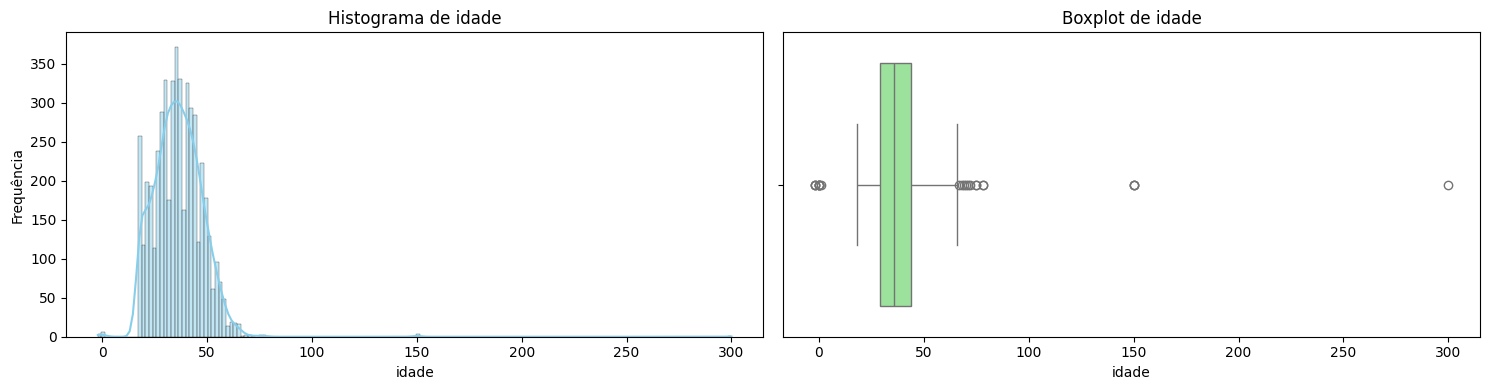

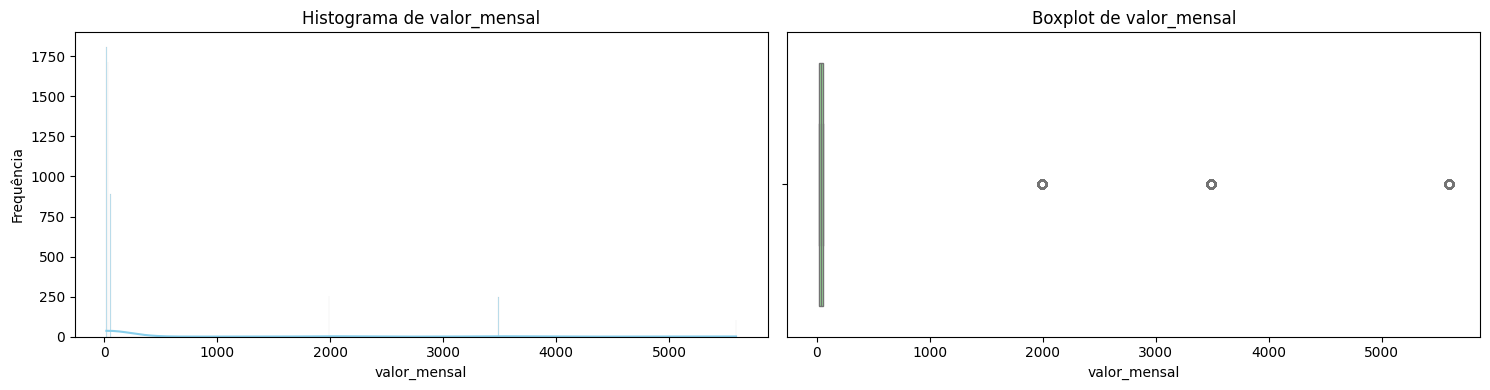

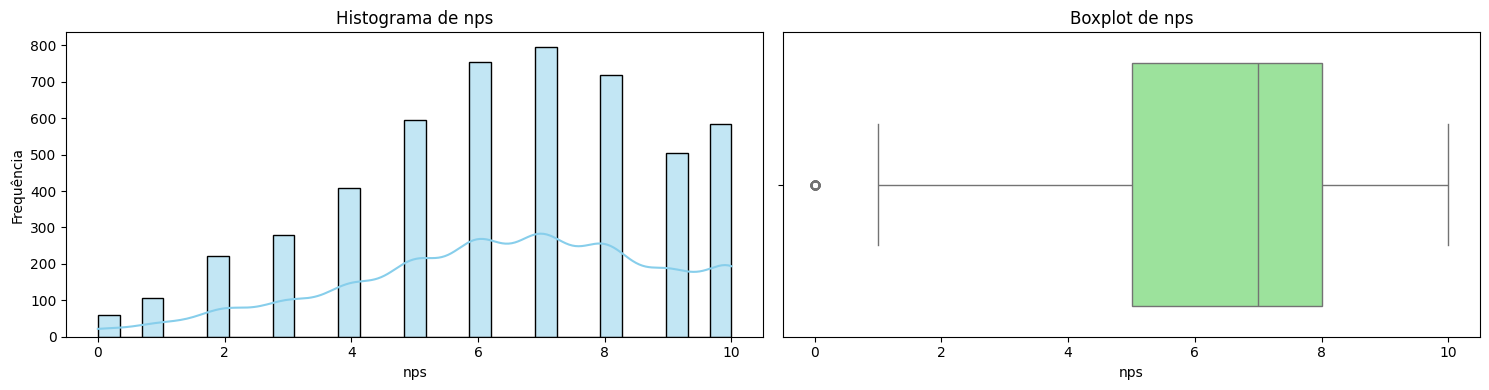

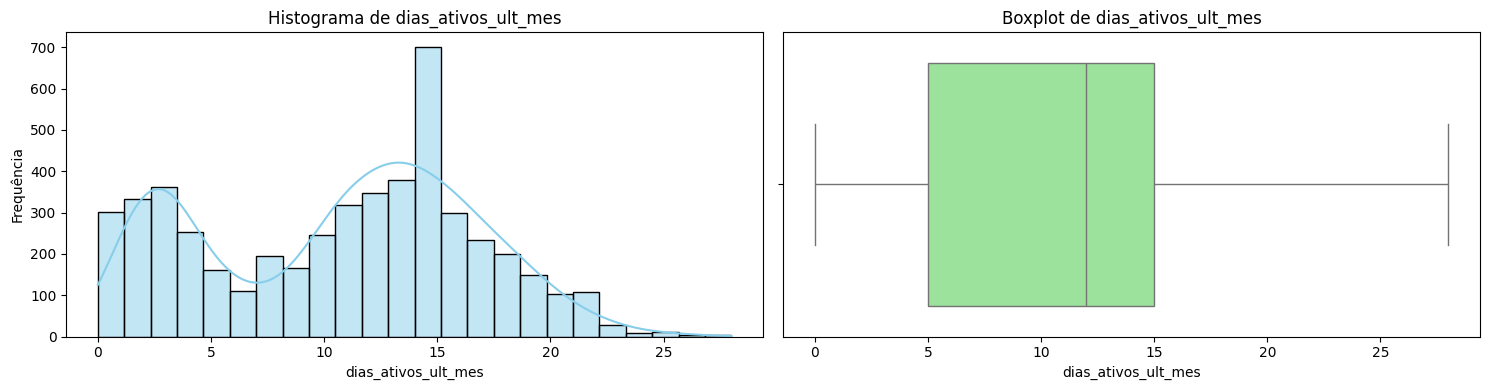

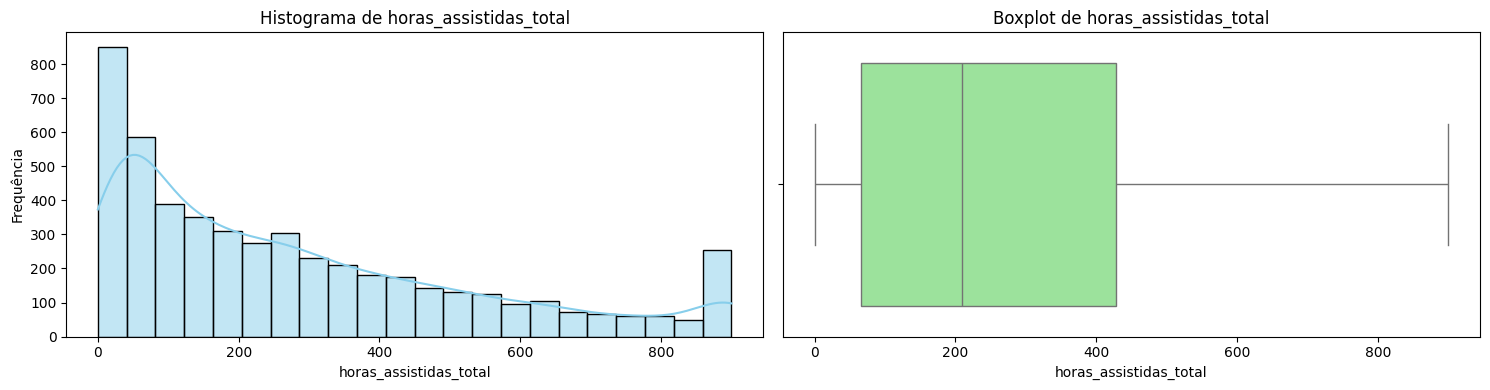

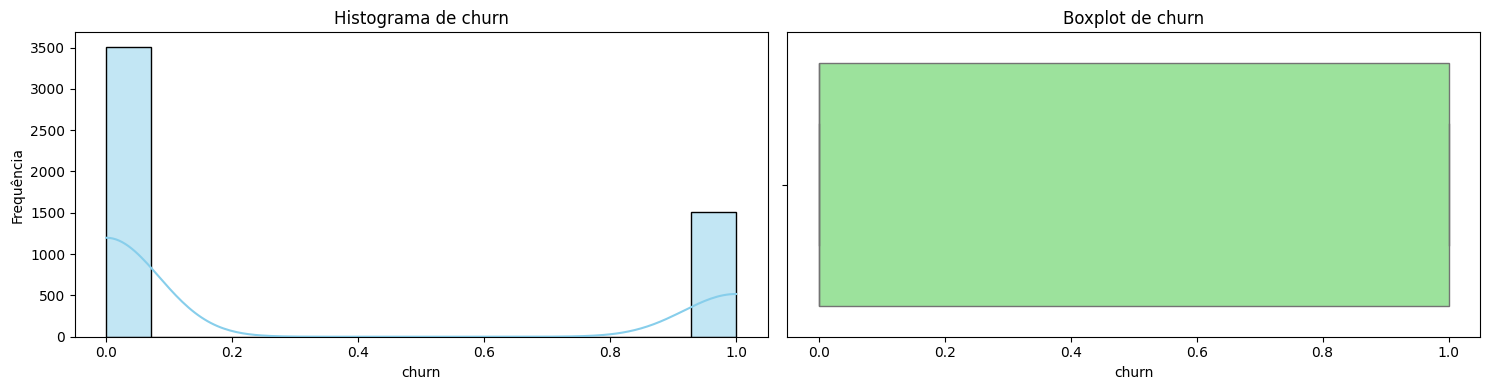

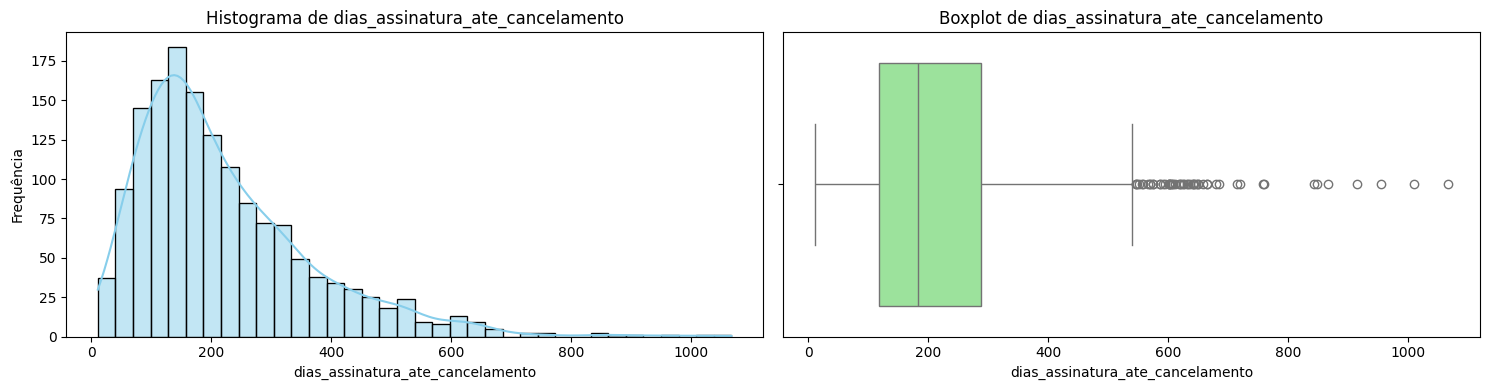

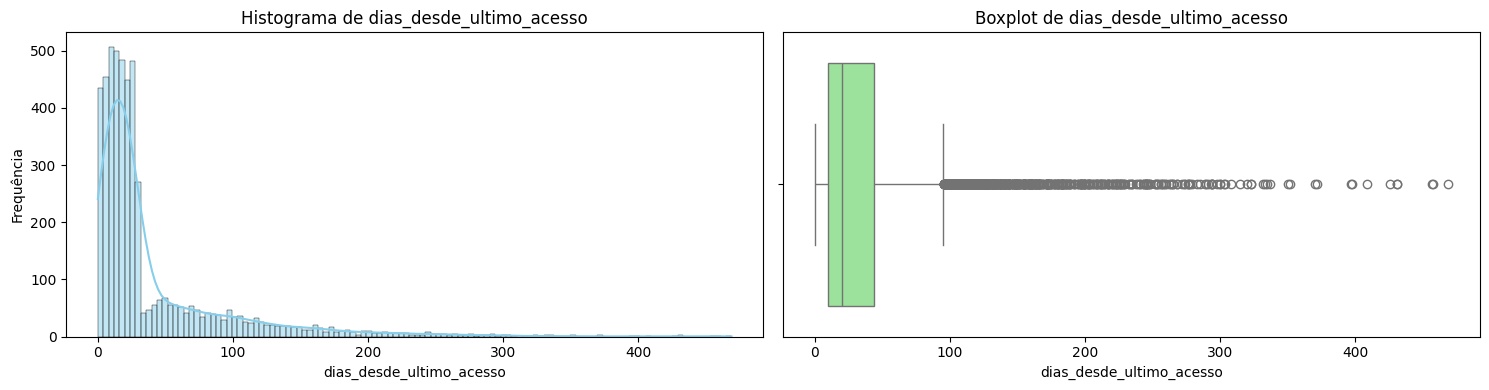

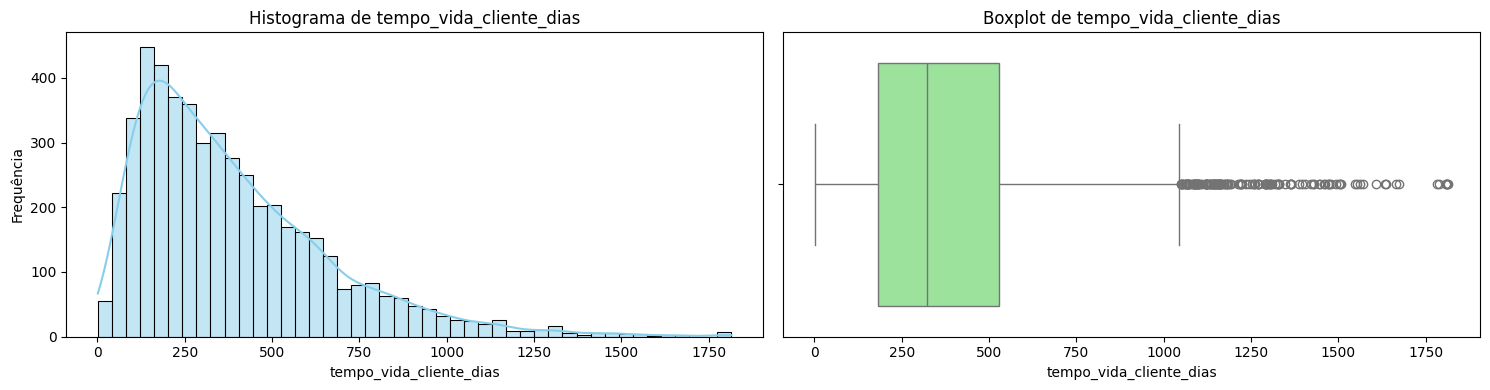

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de colunas numéricas excluindo 'cliente_id'
colunas_plot = [col for col in colunas_numericas if col != 'cliente_id']

# Criando os gráficos para cada coluna
for col in colunas_plot:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # Histograma
    sns.histplot(df[col], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histograma de {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequência')

    # Boxplot
    sns.boxplot(x=df[col], ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot de {col}')
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

### Filtrando Idades Inconsistentes

Nesta célula, criamos o DataFrame `df_filtrado` a partir do `df` de trabalho e filtramos os registros de clientes que possuem idade menor que 18 anos ou maior que 90 anos.

In [ ]:
# Criando a cópia e aplicando o filtro de idade
df_filtrado = df.copy()

linhas_antes = len(df_filtrado)
df_filtrado = df_filtrado[(df_filtrado['idade'] >= 18) & (df_filtrado['idade'] <= 90)]
linhas_depois = len(df_filtrado)

print("=== Remoção de Idades Inconsistentes (< 18 ou > 90) ===")
print(f"Linhas antes do filtro: {linhas_antes}")
print(f"Linhas após o filtro: {linhas_depois}")
print(f"Total de linhas removidas: {linhas_antes - linhas_depois}")

print("\n=== Estatísticas Descritivas de Idade no DataFrame Filtrado ===")
display(df_filtrado['idade'].describe())

=== Remoção de Idades Inconsistentes (< 18 ou > 90) ===
Linhas antes do filtro: 5024
Linhas após o filtro: 5011
Total de linhas removidas: 13

=== Estatísticas Descritivas de Idade no DataFrame Filtrado ===


,idade
count,5011.000000
mean,36.272401
std,10.615144
min,18.000000
25%,29.000000
50%,36.000000
75%,44.000000
max,78.000000


### Analisando Mensalidades Altas (maiores que R$ 1.000,00)

Vamos filtrar e exibir os registros em que a coluna `valor_mensal` possui valores discrepantes superiores a 1000.

In [ ]:
# Filtrando linhas com valor mensal superior a 1000
mensalidades_altas = df_filtrado[df_filtrado['valor_mensal'] > 1000]

print(f"Quantidade de registros com valor mensal > 1000: {len(mensalidades_altas)}")
display(mensalidades_altas)

Quantidade de registros com valor mensal > 1000: 602


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente_dias
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,2024-01-13,2024-01-31,19,385.0,NaN,0,NaN,18.0,304
14,5581,18,padrão,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,2024-01-27,2024-01-31,15,160.7,NaN,0,NaN,4.0,193
29,5979,31,padrão,Mensal,3490.0,Sudeste,instagram,10,2023-08-22,NaT,2024-01-03,2024-01-31,14,117.2,NaN,0,NaN,28.0,162
34,1433,56,padrão,Anual,3490.0,NaN,orgânico,9,2023-04-14,NaT,2024-01-22,2024-01-31,11,180.4,NaN,0,NaN,9.0,292
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,2023-11-25,2024-01-31,6,47.8,problema tecnico,1,75.0,67.0,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,padrão,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,2024-01-13,2024-01-31,20,900.0,NaN,0,NaN,18.0,1156
4991,2396,23,padrão,Anual,3490.0,Nordeste,orgânico,8,2021-04-14,NaT,2024-01-26,2024-01-31,18,900.0,NaN,0,NaN,5.0,1022
5000,5926,37,padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,2024-01-07,2024-01-31,9,243.6,NaN,0,NaN,24.0,426
5006,4388,18,básico,Anual,1990.0,Nordeste,instagram,9,2023-05-03,NaT,2024-01-09,2024-01-31,11,160.6,NaN,0,NaN,22.0,273


### Contagem de Valores Distintos de `valor_mensal`

Vamos listar todos os valores únicos presentes na mensalidade dos clientes para entender a distribuição das tarifas normais e das tarifas com possíveis anomalias de digitação.

In [ ]:
# Contando os valores distintos da coluna valor_mensal
contagem_valores_mensais = df_filtrado['valor_mensal'].value_counts(dropna=False)

print("=== Valores Distintos e Frequências na Coluna 'valor_mensal' ===")
display(contagem_valores_mensais)

=== Valores Distintos e Frequências na Coluna 'valor_mensal' ===


,count
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104


### Corrigindo a Escala de `valor_mensal`

Nesta etapa, dividimos por 100 todos os valores da coluna `valor_mensal` superiores a 100 para ajustar o erro de digitação dos centavos nos registros correspondentes.

In [ ]:
# Corrigindo os valores maiores que 100 na coluna valor_mensal
df_filtrado.loc[df_filtrado['valor_mensal'] > 100, 'valor_mensal'] = df_filtrado['valor_mensal'] / 100

# Verificando novamente os valores únicos após a correção
print("=== Valores Distintos e Frequências Após a Correção ===")
display(df_filtrado['valor_mensal'].value_counts(dropna=False))

print("\n=== Estatísticas Descritivas Atualizadas de valor_mensal ===")
display(df_filtrado['valor_mensal'].describe())

=== Valores Distintos e Frequências Após a Correção ===


,count
valor_mensal,
19.9,2058
34.9,1958
55.9,995



=== Estatísticas Descritivas Atualizadas de valor_mensal ===


,valor_mensal
count,5011.000000
mean,32.909379
std,13.268218
min,19.900000
25%,19.900000
50%,34.900000
75%,34.900000
max,55.900000


### Criação de Novas Variáveis

Nesta célula, adicionamos as novas métricas ao DataFrame de trabalho (`df_filtrado`):
1. **`recencia`**: Dias entre o último acesso e a data de extração.
2. **`meses_assinatura`**: Tempo total de permanência do cliente convertido em meses (tempo de vida em dias dividido por 30).
3. **`receita_acumulada`**: Estimativa da receita total gerada pelo cliente (`valor_mensal` $\times$ `meses_assinatura`).

In [ ]:
# 1. recencia = data_extracao - data_ultimo_acesso (em dias)
df_filtrado['recencia'] = (df_filtrado['data_extracao'] - df_filtrado['data_ultimo_acesso']).dt.days

# 2. meses_assinatura = tempo_vida_cliente_dias / 30
# 'tempo_vida_cliente_dias' já foi calculado anteriormente considerando se o cliente está ativo ou cancelado
df_filtrado['meses_assinatura'] = df_filtrado['tempo_vida_cliente_dias'] / 30.0

# 3. receita_acumulada = valor_mensal * meses_assinatura
df_filtrado['receita_acumulada'] = df_filtrado['valor_mensal'] * df_filtrado['meses_assinatura']

# Exibindo estatísticas descritivas das novas variáveis criadas
print("=== Estatísticas Descritivas das Novas Colunas ===")
display(df_filtrado[['recencia', 'meses_assinatura', 'receita_acumulada']].describe())

# Exibindo uma amostra prática para validação visual
print("\n=== Amostra dos Dados Calculados (Primeiras 10 linhas) ===")
colunas_visualizacao = [
    'plano', 'valor_mensal', 'data_assinatura', 'data_cancelamento',
    'data_ultimo_acesso', 'recencia', 'meses_assinatura', 'receita_acumulada'
]
display(df_filtrado[colunas_visualizacao].head(10))

=== Estatísticas Descritivas das Novas Colunas ===


,recencia,meses_assinatura,receita_acumulada
count,4961.000000,5011.000000,5011.000000
mean,40.452731,12.950376,428.914295
std,55.112223,9.186362,371.527653
min,0.000000,0.033333,0.663333
25%,10.000000,6.033333,168.585000
50%,20.000000,10.766667,321.080000
75%,44.000000,17.600000,570.033333
max,469.000000,60.500000,2893.756667



=== Amostra dos Dados Calculados (Primeiras 10 linhas) ===


,plano,valor_mensal,data_assinatura,data_cancelamento,data_ultimo_acesso,recencia,meses_assinatura,receita_acumulada
0,básico,19.9,2023-04-11,NaT,2024-01-29,2.0,9.833333,195.683333
1,padrão,34.9,2022-06-02,NaT,2024-01-30,1.0,20.266667,707.306667
2,premium,55.9,2021-03-20,2022-11-17,2022-10-31,457.0,20.233333,1131.043333
3,básico,19.9,2023-04-02,NaT,2024-01-13,18.0,10.133333,201.653333
4,básico,19.9,2023-04-21,NaT,2024-01-16,15.0,9.500000,189.050000
5,premium,55.9,2022-11-22,NaT,2024-01-20,11.0,14.500000,810.550000
6,básico,19.9,2023-10-12,2023-12-28,2023-12-09,53.0,2.566667,51.076667
7,padrão,34.9,2022-01-21,NaT,2024-01-12,19.0,24.666667,860.866667
8,básico,19.9,2023-04-26,2023-12-17,2023-12-07,55.0,7.833333,155.883333
9,básico,19.9,2023-10-07,NaT,2024-01-25,6.0,3.866667,76.946667


### Criando o DataFrame `df_analise` com Filtro de Tempo de Assinatura (>= 220 dias)

Vamos filtrar o `df_filtrado` calculando a diferença em dias entre a `data_extracao` e a `data_assinatura` e selecionando apenas os registros com diferença de pelo menos 220 dias.

In [ ]:
# Calculando a diferença em dias entre data_extracao e data_assinatura
diff_data_assinatura_data_extracao = (df_filtrado['data_extracao'] - df_filtrado['data_assinatura']).dt.days

# Criando o novo DataFrame contendo apenas registros com diferença >= 220 dias
df_analise = df_filtrado[diff_data_assinatura_data_extracao >= 220].copy()

# Exibindo informações sobre o resultado da filtragem
print("=== Criação do DataFrame df_analise (>= 220 dias) ===")
print(f"Quantidade de registros no df_filtrado: {len(df_filtrado)}")
print(f"Quantidade de registros no df_analise: {len(df_analise)}")
print(f"Registros removidos: {len(df_filtrado) - len(df_analise)}")

# Visualizando as primeiras linhas de df_analise
display(df_analise.head())

=== Criação do DataFrame df_analise (>= 220 dias) ===
Quantidade de registros no df_filtrado: 5011
Quantidade de registros no df_analise: 3668
Registros removidos: 1343


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente_dias,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,2.0,295,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,1.0,608,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,457.0,607,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,18.0,304,18.0,10.133333,201.653333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,15.0,285,15.0,9.500000,189.050000


### Análise de Churn utilizando `df_analise`

Nesta seção, investigaremos a relação entre o churn (0 ou 1) e as variáveis numéricas e categóricas selecionadas para identificar padrões e comportamentos que influenciam na retenção de clientes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Criando as variáveis de diferença faltantes que foram pedidas na análise:
# 1. diff_data_assinatura_data_ultimo_acesso
df_analise['diff_data_assinatura_data_ultimo_acesso'] = (df_analise['data_ultimo_acesso'] - df_analise['data_assinatura']).dt.days

# 2. diff_data_assinatura_data_extracao (que já calculamos para fazer o filtro anterior)
df_analise['diff_data_assinatura_data_extracao'] = (df_analise['data_extracao'] - df_analise['data_assinatura']).dt.days

#### 1. Análise das Variáveis Numéricas

Vamos iterar sobre cada variável numérica, plotar o histograma de densidade sobreposto e calcular o resumo estatístico detalhado para cada grupo de churn.


 ANÁLISE DA VARIÁVEL NUMÉRICA: IDADE 


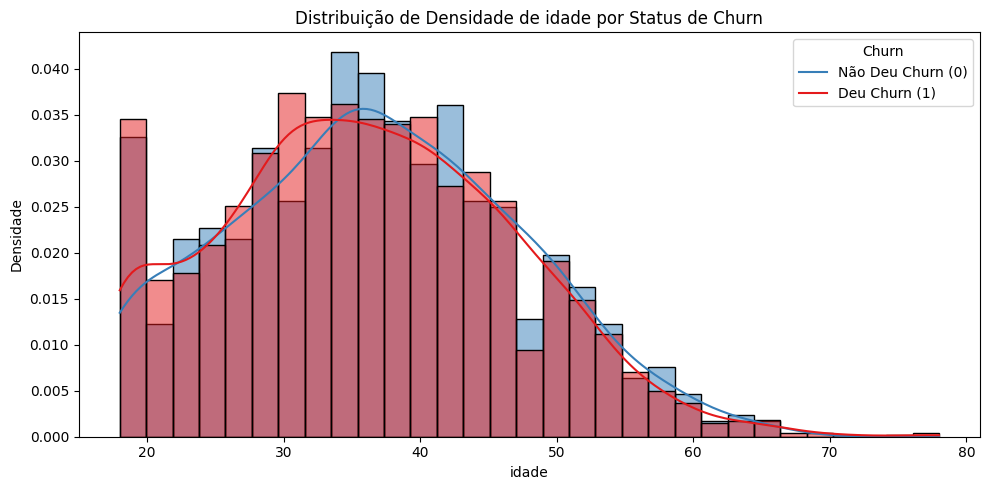

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,36.125540,36.632883
std,10.633567,10.600266
min,18.000000,18.000000
25%,29.000000,29.000000
50%,36.000000,36.000000
75%,44.000000,44.000000
max,78.000000,66.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: VALOR_MENSAL 


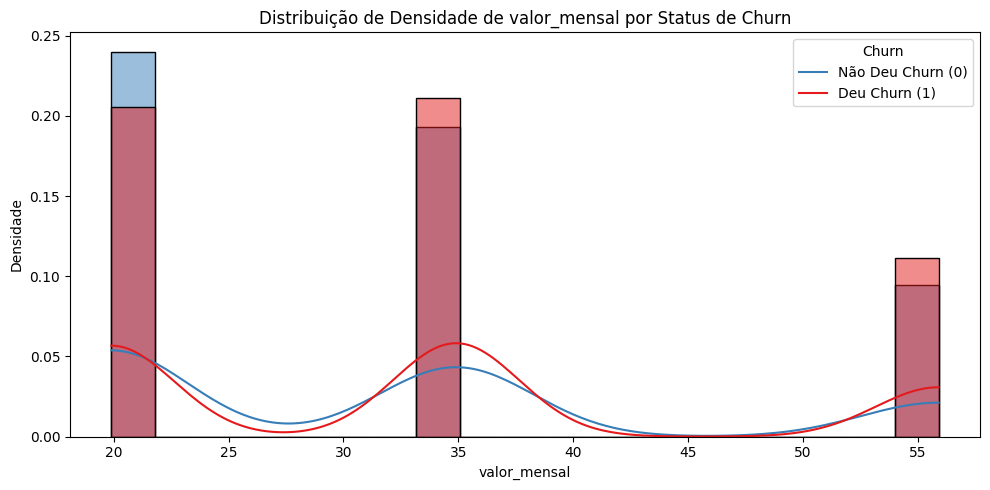

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,33.496043,31.835811
std,13.370968,13.119920
min,19.900000,19.900000
25%,19.900000,19.900000
50%,34.900000,34.900000
75%,34.900000,34.900000
max,55.900000,55.900000



 ANÁLISE DA VARIÁVEL NUMÉRICA: NPS 


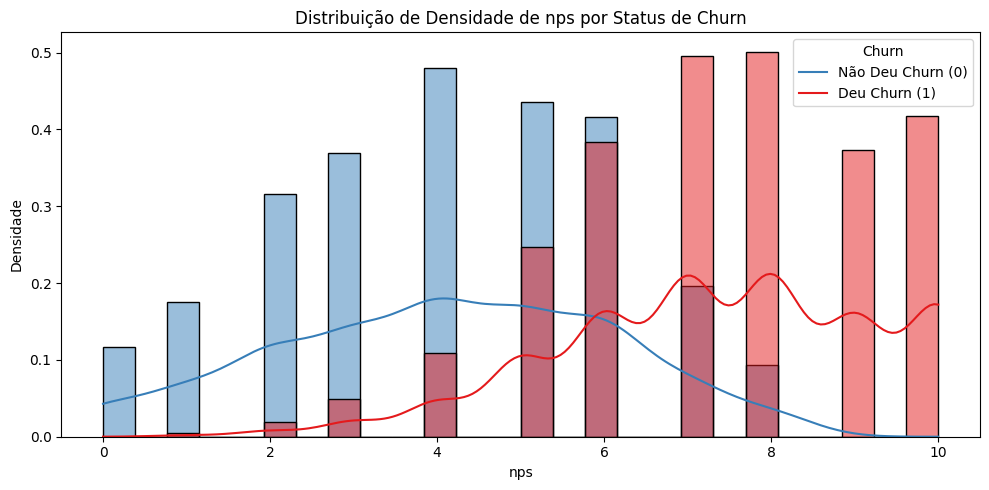

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,7.376978,4.090090
std,1.877014,2.004165
min,1.000000,0.000000
25%,6.000000,3.000000
50%,7.000000,4.000000
75%,9.000000,6.000000
max,10.000000,8.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: DIAS_ATIVOS_ULT_MES 


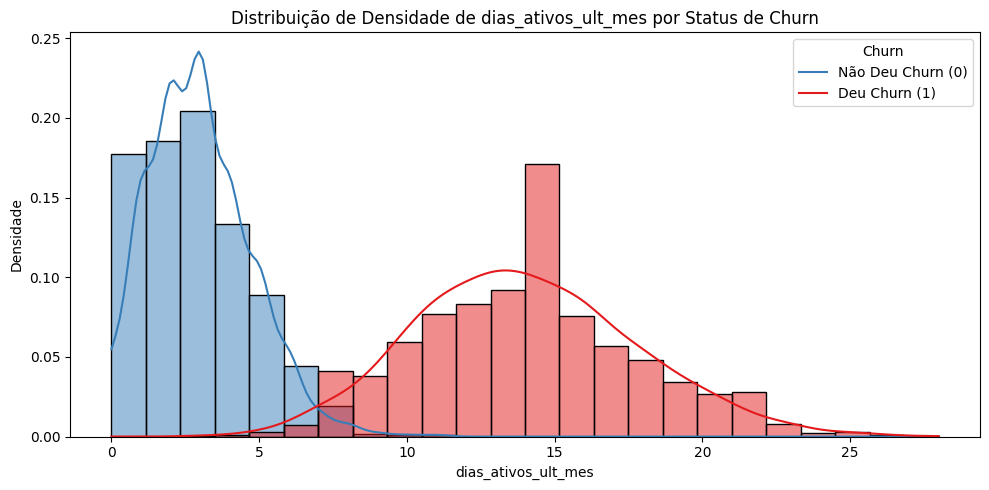

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,13.995324,2.967342
std,3.755046,1.721950
min,3.000000,0.000000
25%,11.000000,2.000000
50%,14.000000,3.000000
75%,16.000000,4.000000
max,28.000000,11.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: HORAS_ASSISTIDAS_TOTAL 


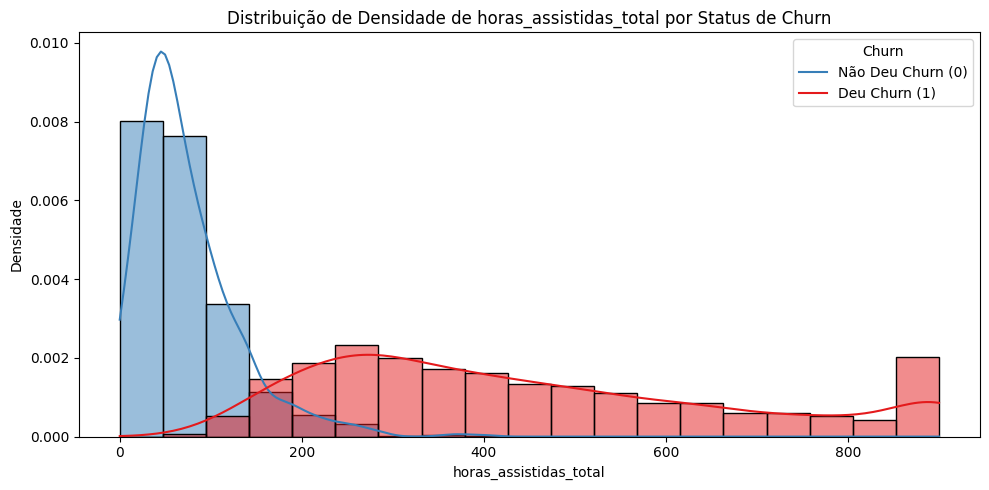

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,448.891475,73.143131
std,226.739374,55.191559
min,73.900000,0.000000
25%,265.450000,35.925000
50%,395.600000,58.950000
75%,600.900000,96.600000
max,900.000000,400.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: DIFF_DATA_ASSINATURA_DATA_ULTIMO_ACESSO 


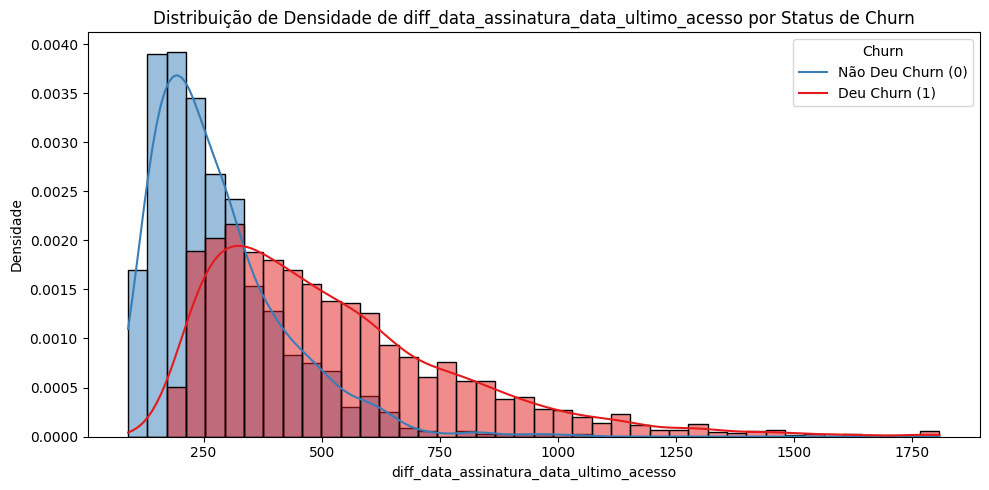

,Não Deu Churn (0),Deu Churn (1)
count,2755.000000,878.000000
mean,528.301270,278.715262
std,266.179458,138.580418
min,192.000000,90.000000
25%,327.000000,176.000000
50%,465.000000,244.000000
75%,659.000000,342.500000
max,1809.000000,1040.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: DIFF_DATA_ASSINATURA_DATA_EXTRACAO 


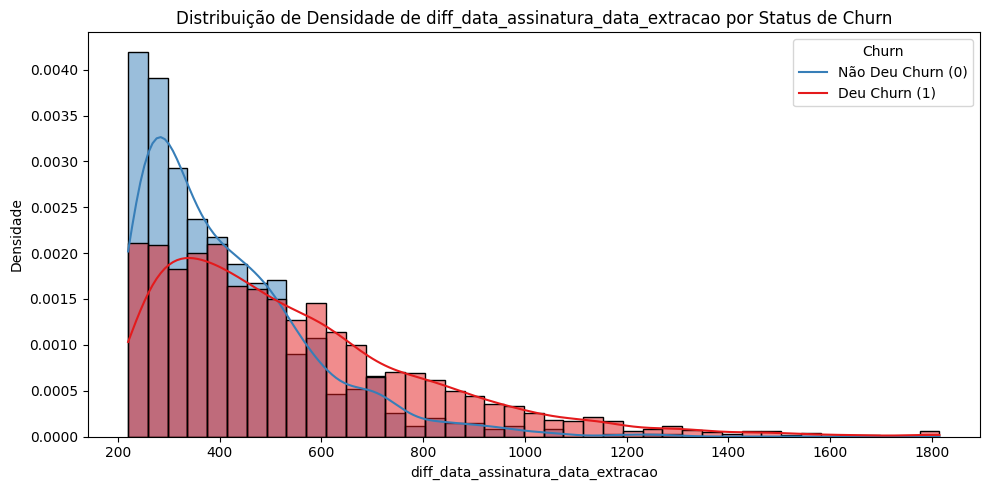

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,542.666187,409.548423
std,265.461831,166.733604
min,220.000000,220.000000
25%,341.000000,282.000000
50%,481.000000,364.500000
75%,673.250000,495.000000
max,1815.000000,1276.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: RECENCIA 


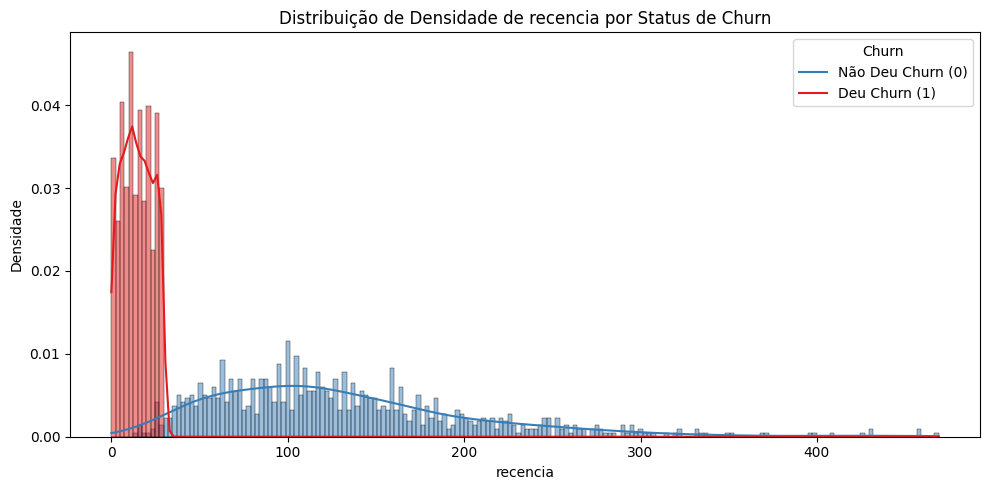

,Não Deu Churn (0),Deu Churn (1)
count,2755.000000,878.000000
mean,14.603993,130.011390
std,8.493044,74.106997
min,0.000000,13.000000
25%,8.000000,75.250000
50%,14.000000,117.000000
75%,22.000000,165.000000
max,29.000000,469.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: MESES_ASSINATURA 


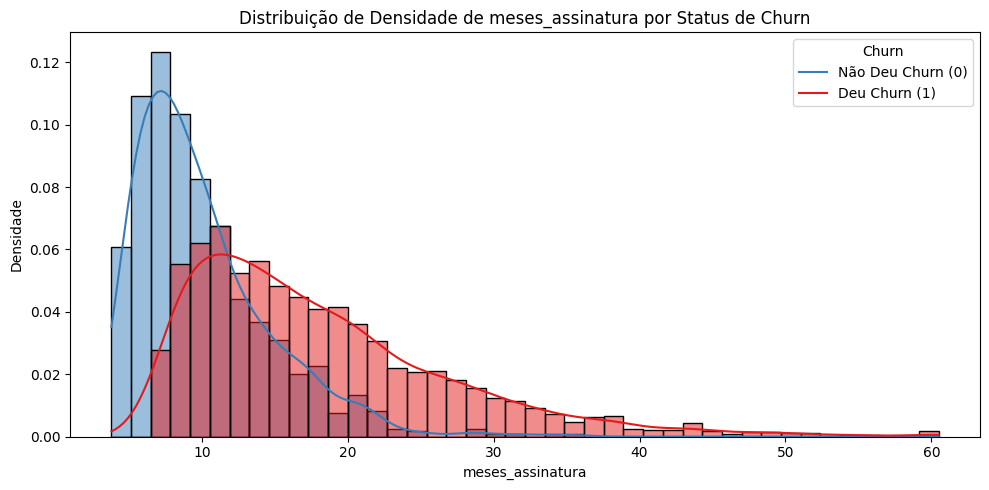

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,18.088873,10.006156
std,8.848728,4.615595
min,7.333333,3.800000
25%,11.366667,6.666667
50%,16.033333,8.900000
75%,22.441667,12.108333
max,60.500000,35.566667



 ANÁLISE DA VARIÁVEL NUMÉRICA: RECEITA_ACUMULADA 


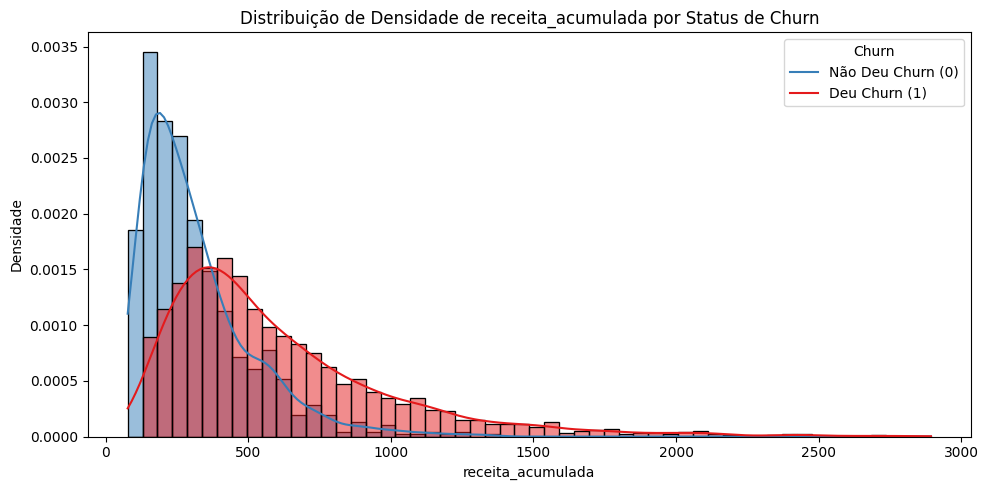

,Não Deu Churn (0),Deu Churn (1)
count,2780.000000,888.000000
mean,605.311556,315.519917
std,396.917467,195.137065
min,145.933333,77.610000
25%,329.013333,172.173333
50%,491.508333,262.680000
75%,762.103333,392.043333
max,2893.756667,1341.600000


In [ ]:
vars_numericas = [
    "idade", "valor_mensal", "nps", "dias_ativos_ult_mes",
    "horas_assistidas_total", "diff_data_assinatura_data_ultimo_acesso",
    "diff_data_assinatura_data_extracao", "recencia",
    "meses_assinatura", "receita_acumulada"
]

for col in vars_numericas:
    print(f"\n" + "="*80)
    print(f" ANÁLISE DA VARIÁVEL NUMÉRICA: {col.upper()} ")
    print("="*80)

    # 1. Histograma de densidade sobreposto
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df_analise, x=col, hue="churn", kde=True, stat="density", common_norm=False, palette="Set1", alpha=0.5)
    plt.title(f"Distribuição de Densidade de {col} por Status de Churn")
    plt.xlabel(col)
    plt.ylabel("Densidade")
    plt.legend(title="Churn", labels=["Não Deu Churn (0)", "Deu Churn (1)"])
    plt.tight_layout()
    plt.show()

    # 2. Tabela de estatísticas descritivas por grupo de churn
    estatisticas = df_analise.groupby("churn")[col].describe().T
    estatisticas.columns = ["Não Deu Churn (0)", "Deu Churn (1)"]
    display(estatisticas)

#### 2. Análise das Variáveis Categóricas

Vamos calcular a taxa de churn em porcentagem para cada categoria pertencente às variáveis categóricas selecionadas.

In [ ]:
vars_categoricas = ["plano", "ciclo", "regiao", "canal_aquisicao"]

for col in vars_categoricas:
    print(f"\n" + "="*80)
    print(f" TAXA DE CHURN POR CATEGORIA: {col.upper()} ")
    print("="*80)

    # Calculando a taxa de churn por categoria
    # Como 'churn' é uma variável binária (0 ou 1), a média equivale à proporção (taxa) de churn
    churn_rate = df_analise.groupby(col).agg(
        total_clientes=('churn', 'count'),
        total_churn=('churn', 'sum'),
        taxa_churn_pct=('churn', lambda x: x.mean() * 100)
    ).reset_index()

    # Formatando para exibição amigável
    churn_rate['taxa_churn_pct'] = churn_rate['taxa_churn_pct'].map('{:.2f}%'.format)
    display(churn_rate.sort_values(by='total_clientes', ascending=False))


 TAXA DE CHURN POR CATEGORIA: PLANO 


,plano,total_clientes,total_churn,taxa_churn_pct
0,básico,1486,404,27.19%
1,padrão,1436,325,22.63%
2,premium,746,159,21.31%



 TAXA DE CHURN POR CATEGORIA: CICLO 


,ciclo,total_clientes,total_churn,taxa_churn_pct
1,Mensal,2752,668,24.27%
0,Anual,916,220,24.02%



 TAXA DE CHURN POR CATEGORIA: REGIAO 


,regiao,total_clientes,total_churn,taxa_churn_pct
3,Sudeste,1464,338,23.09%
1,Nordeste,719,172,23.92%
4,Sul,707,174,24.61%
0,Centro-Oeste,353,93,26.35%
2,Norte,297,76,25.59%



 TAXA DE CHURN POR CATEGORIA: CANAL_AQUISICAO 


,canal_aquisicao,total_clientes,total_churn,taxa_churn_pct
2,instagram,1125,280,24.89%
3,orgânico,1111,255,22.95%
1,indicação,797,181,22.71%
0,google,635,172,27.09%


### Análise de Pareto dos Motivos de Cancelamento

Nesta seção, identificamos e normalizamos os motivos de cancelamento dos clientes no `df_filtrado` para traçar uma Tabela e Gráfico de Pareto. Isso nos ajudará a focar nos principais problemas que causam o Churn.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata

# Função para remover acentos e normalizar strings
def normalizar_texto(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).strip().lower()
    # Remove acentos utilizando unicodedata
    texto_normalizado = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')
    return texto_normalizado

# Aplicando a normalização na coluna de motivos de cancelamento
df_filtrado['motivo_cancelamento_limpo'] = df_filtrado['motivo_cancelamento'].apply(normalizar_texto)

# Filtrando apenas registros que possuem motivo preenchido (ignorando nulos)
df_motivos = df_filtrado[df_filtrado['motivo_cancelamento_limpo'].notna()].copy()

# 1. Contando os motivos de cancelamento de forma decrescente
pareto_df = df_motivos['motivo_cancelamento_limpo'].value_counts().reset_index()
pareto_df.columns = ['Motivo', 'Quantidade']

# 2. Calculando a porcentagem individual e acumulada
total_cancelamentos = pareto_df['Quantidade'].sum()
pareto_df['Porcentagem'] = (pareto_df['Quantidade'] / total_cancelamentos) * 100
pareto_df['Porcentagem_Acumulada'] = pareto_df['Porcentagem'].cumsum()

print("=== Tabela de Pareto dos Motivos de Cancelamento ===")
display(pareto_df)

# 3. Identificando os principais motivos que concentram cerca de 80% do Churn
principais_motivos = pareto_df[pareto_df['Porcentagem_Acumulada'] - pareto_df['Porcentagem'] < 80]['Motivo'].tolist()
print(f"\nOs motivos que concentram cerca de 80% dos cancelamentos são: {principais_motivos}")

=== Tabela de Pareto dos Motivos de Cancelamento ===


,Motivo,Quantidade,Porcentagem,Porcentagem_Acumulada
0,preco,507,33.553938,33.553938
1,pouco conteudo novo,384,25.413633,58.967571
2,problema tecnico,249,16.479153,75.446724
3,falta de tempo,174,11.515553,86.962277
4,concorrente,130,8.603574,95.565850
5,outro,67,4.434150,100.000000



Os motivos que concentram cerca de 80% dos cancelamentos são: ['preco', 'pouco conteudo novo', 'problema tecnico', 'falta de tempo']


/tmp/ipykernel_1033/1926643856.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(pareto_df['Motivo'], rotation=45, ha='right')


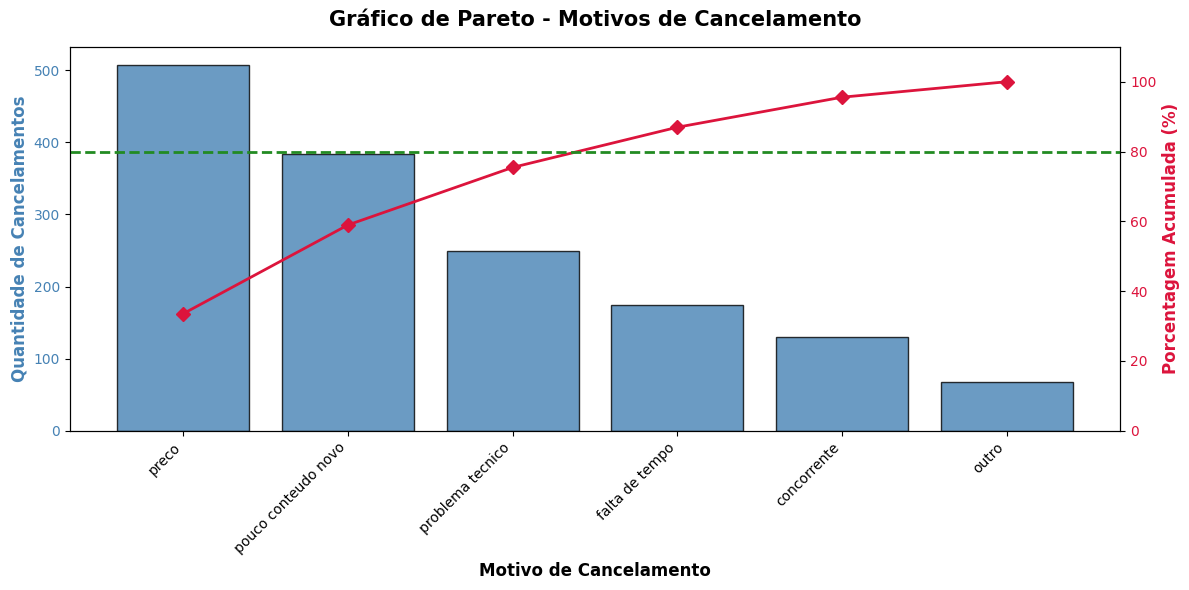

In [ ]:
# 4. Plotando o Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo 1: Gráfico de Barras para as Quantidades
color_bars = 'steelblue'
ax1.bar(pareto_df['Motivo'], pareto_df['Quantidade'], color=color_bars, alpha=0.8, edgecolor='black', label='Quantidade')
ax1.set_xlabel('Motivo de Cancelamento', fontsize=12, fontweight='bold')
ax1.set_ylabel('Quantidade de Cancelamentos', color=color_bars, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_bars)
ax1.set_xticklabels(pareto_df['Motivo'], rotation=45, ha='right')

# Eixo 2: Linha para a Porcentagem Acumulada
ax2 = ax1.twinx()
color_line = 'crimson'
ax2.plot(pareto_df['Motivo'], pareto_df['Porcentagem_Acumulada'], color=color_line, marker='D', ms=7, linestyle='-', linewidth=2, label='% Acumulada')
ax2.set_ylabel('Porcentagem Acumulada (%)', color=color_line, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.set_ylim(0, 110)

# Adicionando a linha de referência horizontal de 80%
ax2.axhline(80, color='forestgreen', linestyle='--', linewidth=2, label='Limite de 80%')

# Título e ajustes finais
plt.title('Gráfico de Pareto - Motivos de Cancelamento', fontsize=15, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

### Análise de Funil de Conversão do Onboarding

Nesta nova seção, começamos importando os dados de eventos para analisar o funil de onboarding a partir do arquivo `funil_eventos.csv`.

In [ ]:
import pandas as pd

caminho_funil = '/content/drive/MyDrive/Data Science/funil_eventos.csv'

try:
    # Carregando o DataFrame
    df_funil = pd.read_csv(caminho_funil)
    print(f"Quantidade de registros original: {len(df_funil)}")

    # Removendo linhas duplicadas
    df_funil = df_funil.drop_duplicates()
    print(f"Quantidade de registros após remover duplicadas: {len(df_funil)}")

    # Exibindo as primeiras linhas
    display(df_funil.head())
except Exception as e:
    print(f"Erro ao processar o arquivo: {e}")

Quantidade de registros original: 12886
Quantidade de registros após remover duplicadas: 12836


,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula


### Padronização e Limpeza da Coluna `etapa`

In [ ]:
# Visualizando os valores únicos antes da padronização
print("=== Valores únicos originais da coluna 'etapa' ===")
print(df_funil['etapa'].unique())

# Padronizando: minúsculo, sem espaços nas extremidades e substituindo espaços internos por '_'
df_funil['etapa'] = df_funil['etapa'].astype(str).str.strip().str.lower().str.replace(' ', '_')

# Visualizando após a padronização
print("\n=== Valores únicos padronizados ===")
print(df_funil['etapa'].unique())

=== Valores únicos originais da coluna 'etapa' ===
['assistiu_1a_aula' 'criou_conta' 'visitou_site' 'renovou' 'assinou plano'
 'assinou_plano' 'Assinou_Plano']

=== Valores únicos padronizados ===
['assistiu_1a_aula' 'criou_conta' 'visitou_site' 'renovou' 'assinou_plano']


### Construção da Tabela de Conversão do Funil de Onboarding

Vamos calcular a quantidade de clientes únicos por etapa na ordem lógica do funil de onboarding, computando a taxa de conversão em relação à etapa anterior e em relação ao topo do funil (visitou o site).

In [ ]:
# Definindo a ordem lógica das etapas do funil
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']

# Contando usuários únicos por etapa
usuarios_por_etapa = []
for etapa in ordem_funil:
    # Filtramos os clientes que alcançaram pelo menos esta etapa
    qtd_unicos = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()
    usuarios_por_etapa.append(qtd_unicos)

# Criando o DataFrame do funil
df_funil_analise = pd.DataFrame({
    'Etapa': ordem_funil,
    'Usuarios': usuarios_por_etapa
})

# 1. Calculando a Conversão em Relação ao Topo (visitou_site)
topo_funil = df_funil_analise.loc[0, 'Usuarios']
df_funil_analise['Conversao_Topo_Pct'] = (df_funil_analise['Usuarios'] / topo_funil) * 100

# 2. Calculando a Conversão em Relação à Etapa Anterior
conversao_anterior = [100.0]  # A primeira etapa (topo) começa em 100%
for i in range(1, len(df_funil_analise)):
    usuarios_atual = df_funil_analise.loc[i, 'Usuarios']
    usuarios_anterior = df_funil_analise.loc[i-1, 'Usuarios']
    if usuarios_anterior > 0:
        tx = (usuarios_atual / usuarios_anterior) * 100
    else:
        tx = 0.0
    conversao_anterior.append(tx)

df_funil_analise['Conversao_Anterior_Pct'] = conversao_anterior

# Formatando as tabelas com percentuais amigáveis para exibição
tabela_exibicao = df_funil_analise.copy()
tabela_exibicao['Conversao_Anterior_Pct'] = tabela_exibicao['Conversao_Anterior_Pct'].map('{:.2f}%'.format)
tabela_exibicao['Conversao_Topo_Pct'] = tabela_exibicao['Conversao_Topo_Pct'].map('{:.2f}%'.format)

print("=== Tabela de Métricas do Funil ===")
display(tabela_exibicao)

=== Tabela de Métricas do Funil ===


,Etapa,Usuarios,Conversao_Topo_Pct,Conversao_Anterior_Pct
0,visitou_site,5000,100.00%,100.00%
1,criou_conta,3377,67.54%,67.54%
2,assistiu_1a_aula,2698,53.96%,79.89%
3,assinou_plano,1066,21.32%,39.51%
4,renovou,695,13.90%,65.20%


### Identificando o Maior Gargalo do Funil

O gargalo é definido pela etapa que apresenta a menor conversão quando comparada com a etapa anterior (ou seja, onde houve a maior taxa de desistência/queda percentual).

In [ ]:
# Identificando a etapa com menor taxa de conversão em relação ao passo anterior (ignorando o topo que começa em 100%)
idx_gargalo = df_funil_analise.iloc[1:]['Conversao_Anterior_Pct'].idxmin()
etapa_gargalo = df_funil_analise.loc[idx_gargalo, 'Etapa']
taxa_gargalo = df_funil_analise.loc[idx_gargalo, 'Conversao_Anterior_Pct']
queda_gargalo = 100.0 - taxa_gargalo

print(f"O maior gargalo do funil está na transição para a etapa: '{etapa_gargalo}'")
print(f"Apenas {taxa_gargalo:.2f}% dos usuários da etapa anterior avançaram para ela.")
print(f"Isso representa uma perda/queda de {queda_gargalo:.2f}% dos usuários nessa etapa.")

O maior gargalo do funil está na transição para a etapa: 'assinou_plano'
Apenas 39.51% dos usuários da etapa anterior avançaram para ela.
Isso representa uma perda/queda de 60.49% dos usuários nessa etapa.


### Visualização Gráfica do Funil de Conversão

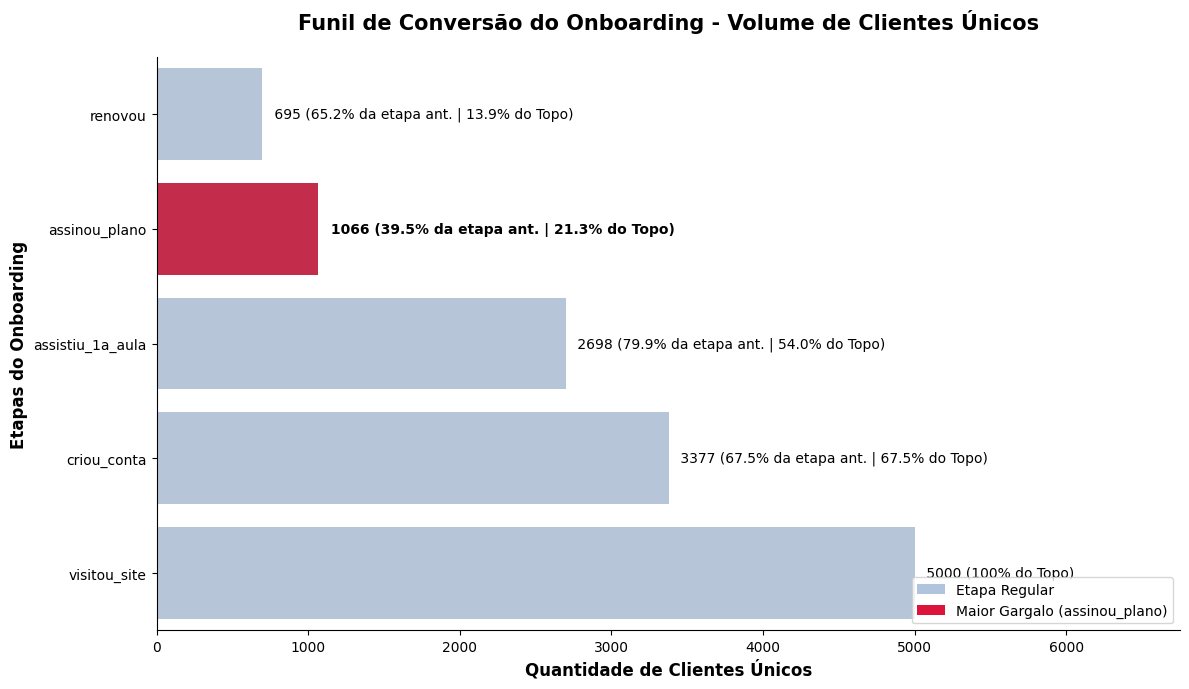

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

# Definindo as cores: destacando o gargalo em vermelho e as outras barras em cinza-azulado
cores = [
    'crimson' if etapa == etapa_gargalo else 'lightsteelblue'
    for etapa in df_funil_analise['Etapa']
]

# Plotando o gráfico de barras horizontais
ax = sns.barplot(
    x='Usuarios',
    y='Etapa',
    data=df_funil_analise,
    palette=cores,
    hue='Etapa',
    legend=False
)

# Invertendo o eixo Y para que o topo do funil fique em cima
plt.gca().invert_yaxis()

# Adicionando rótulos com a quantidade e as taxas nas barras
for i, barra in enumerate(ax.patches):
    qtd = int(barra.get_width())
    pct_anterior = df_funil_analise.loc[i, 'Conversao_Anterior_Pct']
    pct_topo = df_funil_analise.loc[i, 'Conversao_Topo_Pct']

    # Texto de apoio
    if i == 0:
        texto_label = f" {qtd} (100% do Topo)"
    else:
        texto_label = f" {qtd} ({pct_anterior:.1f}% da etapa ant. | {pct_topo:.1f}% do Topo)"

    ax.text(
        qtd + 50,
        barra.get_y() + barra.get_height() / 2,
        texto_label,
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold' if df_funil_analise.loc[i, 'Etapa'] == etapa_gargalo else 'normal'
    )

# Personalizando limites, títulos e eixos
plt.title('Funil de Conversão do Onboarding - Volume de Clientes Únicos', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Quantidade de Clientes Únicos', fontsize=12, fontweight='bold')
plt.ylabel('Etapas do Onboarding', fontsize=12, fontweight='bold')
plt.xlim(0, df_funil_analise['Usuarios'].max() * 1.35)

# Adicionando uma legenda manual explicativa para a cor em destaque
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='lightsteelblue', label='Etapa Regular'),
    Patch(facecolor='crimson', label=f'Maior Gargalo ({etapa_gargalo})')
]
plt.legend(handles=legend_elements, loc='lower right', frameon=True)

sns.despine()
plt.tight_layout()
plt.show()

Há indício de que a retenção piorou nas safras recentes. As curvas de 2023 caem visivelmente mais rápido do que as de 2022, que caem mais rápido que as de 2021. Isso é um sinal de negócio importante: a qualidade da aquisição ou a experiência pode estar se deteriorando.
